# AllData & AllModel: 2016–2025 five-minute charts, every model, with and without SPY

**Data.** S&P 500 ∪ NASDAQ 100 ∪ DJIA 30 members by date (775 PERMNOs, 516–531 a day), 2,514 sessions
from 2016-01-04 to 2025-12-31, five-minute bars from TAQ trades. SPY bars are built with the same filters on
the same clock. Prices are adjusted **point in time**: every window is put on the basis of its last bar
(splits, stock dividends and cash dividends before it are adjusted, nothing after it). Labels use traded
(unadjusted) prices; a label whose horizon contains an ex-date is dropped. Early-close sessions are excluded.

**Split.** Train 2016–2022 · validation 2023 (all model choices) · test 2024–2025 (section 8, run once at the end).

**Grid.** `dir` (return > 0), `vol` (|return| > the stock's training median), `xsdir` (return > cross-sectional
median) × 5 / 15 / 30 / 60 minutes, one sample per stock per hour (stride 12) for every horizon.

**Models per cell** (every model prints its parameter count; for HGB the count is tree nodes):

| model | input |
|---|---|
| `plain` image CNN | 234×234 chart of the stock's 78 bars |
| `plain_spy` image CNN + SPY panel | 468×234: the stock chart with SPY's chart in its own panel below, bar columns aligned |
| `series1d` 1D CNN | the 5 OHLCV series, scaled exactly as the chart is |
| `series1d_spy` 1D CNN + SPY | 10 series: the stock's 5 and SPY's 5 |
| HGB hand features | 20 hand features of the stock window |
| HGB hand + SPY | the same plus 18 SPY / stock-vs-SPY features (SPY returns, realized vol, beta, correlation, idiosyncratic vol, relative return) |

**Resumable**: finished cells are saved on Drive and skipped on a rerun; an unfinished CNN resumes from its last epoch.

## 1. Setup
Copies the data bundle (1.2 GB) from Drive to the Colab disk and unzips it (4.5 GB); a few minutes.

In [1]:
import os, sys, json, shutil, tempfile, zipfile, hashlib
from pathlib import Path

LOCAL_TEST = os.environ.get("ALLDATA_LOCAL_NOTEBOOK_TEST") == "1"     # repository QA only
if LOCAL_TEST:
    HERE = Path(os.environ["ALLDATA_LOCAL_HERE"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    HERE = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel")
BUNDLE = HERE / "alldata_bundle_v1.zip"
assert BUNDLE.is_file(), f"Put alldata_bundle_v1.zip in {HERE}"

LOCAL = Path(tempfile.mkdtemp(prefix="alldata_", dir=None if LOCAL_TEST else "/content"))
STAGE = LOCAL / "bundle"
STAGE.mkdir(parents=True)
shutil.copy2(BUNDLE, LOCAL / "bundle.zip")
with zipfile.ZipFile(LOCAL / "bundle.zip") as z:
    for info in z.infolist():                       # refuse paths escaping the folder
        assert (STAGE / info.filename).resolve().is_relative_to(STAGE.resolve())
    z.extractall(STAGE)
(LOCAL / "bundle.zip").unlink()
def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 24), b""): h.update(b)
    return h.hexdigest()
for rel, d in json.loads((STAGE / "bundle_manifest.json").read_text())["files"].items():
    assert _sha(STAGE / rel) == d["sha256"], f"checksum mismatch: {rel}"
PREPARED = STAGE / "prepared"

# chartcnn/ next to this notebook on Drive wins (easy to edit); otherwise the copy inside the bundle.
CODE = HERE if (HERE / "chartcnn").is_dir() else STAGE
sys.path.insert(0, str(CODE))
import numpy as np, pandas as pd, torch
from IPython.display import display, Markdown
import chartcnn
from chartcnn import grid
from chartcnn.utils import save_json
assert chartcnn.__version__ >= "2026-11-16.1", f"stale chartcnn {chartcnn.__version__} in {CODE}"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("data:", PREPARED, "| code:", CODE, "| device:", DEVICE, torch.cuda.get_device_name() if DEVICE.type == "cuda" else "")

Mounted at /content/drive
chartcnn 2026-11-16.1 loaded from /content/alldata_n06nmhgi/bundle/chartcnn/__init__.py
data: /content/alldata_n06nmhgi/bundle/prepared | code: /content/alldata_n06nmhgi/bundle | device: cuda NVIDIA L4


## 2. Configuration
Change settings here only. **To resume after a disconnect**, set `RUN_ID` to the id printed by the first run and Run all again.

**Data on Colab.** The bundle (`alldata_bundle_v1.zip`, 1.2 GB) is copied from Drive to the Colab disk and unzipped
(4.5 GB). Bars are opened as memory maps and charts are drawn per sample, so no images are stored. The label arrays
take about 6 GB of RAM, which fits the standard runtime; a High-RAM runtime is safer with 8 data-loading workers.
**`QUICK = True`** runs a small first pass (fewer rows, every 5th validation day, horizons 60 and 5 minutes) to check
the whole notebook before the full run; its numbers are rough.

Time budget: the CNNs train on a random `max_train_nn` subset of the training windows (whole years do not fit a Colab
session); HGB uses up to `max_train_hgb`. Early stopping watches every 4th validation day; final validation scores use the
whole of 2023. Rough guess on an L4, not measured on this data: 10–20 min per image CNN and 3–6 min per 1D CNN per cell,
so 6–9 hours for all 12 cells × 4 networks; reruns resume. To get the answers that matter first, the cells run
in the order of `HORIZONS` (the `vol` and `xsdir` cells at 60 and 5 minutes first).

In [2]:
from datetime import datetime, timezone
SMOKE = LOCAL_TEST                                # tiny code check; never a result
assert DEVICE.type == "cuda" or SMOKE, "Select a GPU runtime"

RUN_ID = None                                     # None = new run; or an old RUN_ID to resume it
QUICK = False                                     # True: small first pass (~30-60 min) to check everything runs
SETTINGS = dict(
    learning_rate=1e-5, weight_decay=0.0,         # Adam, as in Jiang-Kelly-Xiu and earlier runs
    batch_size=4 if SMOKE else 128, eval_batch_size=8 if SMOKE else 1024,
    epochs=1 if SMOKE else 8, patience=2, min_delta=1e-5,       # early stop on validation log loss
    channels=[64, 128, 256], head_height=4, dropout=0.5,
    max_train_nn=300_000, max_train_hgb=1_000_000, early_stop_every_kth_day=4,
    amp=True,                                     # bfloat16 autocast on A100/L4/H100; ignored on T4/CPU
    num_workers=0 if SMOKE else min(8, os.cpu_count() or 2),
    seed=69,
)
if QUICK:                                         # fewer rows and days, 2 horizons; numbers are rough
    SETTINGS.update(max_train_nn=40_000, max_train_hgb=200_000, validation_every_kth_day=5, epochs=3)
HORIZONS = [12, 1] if QUICK else [12, 1, 6, 3]    # bars of 5 minutes: 60, 5, 30, 15 minutes (run order)
KINDS = ["vol", "xsdir", "dir"]                   # volatility, relative direction, absolute direction
STRIDE = 12                                       # one sample per stock per hour, for every horizon
ARCHS = ["plain", "plain_spy", "series1d", "series1d_spy"]
CELLS = grid.grid_cells(HORIZONS, KINDS, STRIDE)

RESUME = RUN_ID is not None
RUN_ID = RUN_ID or ("local_smoke" if LOCAL_TEST else datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S"))
RUN_DRIVE, RUN_LOCAL = HERE / "runs" / RUN_ID, LOCAL / "run"
if RESUME:
    assert RUN_DRIVE.exists(), f"{RUN_DRIVE} not found"
else:
    assert LOCAL_TEST or not RUN_DRIVE.exists(), "RUN_ID exists: set RUN_ID to resume it"
RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir(parents=True, exist_ok=True)
save_json(RUN_LOCAL / ("settings_resume.json" if RESUME else "settings.json"),
          dict(settings=SETTINGS, cells=CELLS, archs=ARCHS, quick=QUICK, chartcnn=chartcnn.__version__), RUN_DRIVE)
print("RUN_ID:", RUN_ID, "->", RUN_DRIVE)
print(len(CELLS), "cells:", ", ".join(c["name"] for c in CELLS))

RUN_ID: run_20261116_044159 -> /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/runs/run_20261116_044159
12 cells: vol_h12, xsdir_h12, dir_h12, vol_h1, xsdir_h1, dir_h1, vol_h6, xsdir_h6, dir_h6, vol_h3, xsdir_h3, dir_h3


## 3. Data overview
Sessions, securities and windows per split, as built and audited locally (`manifest.json`).

In [3]:
store = chartcnn.Store(PREPARED)
M = json.loads((PREPARED / "manifest.json").read_text())
print("stocks:", len(M["permnos"]), "| slots:", store.T, "| sessions:", store.T // 78,
      "| early-close sessions excluded:", len(M["config"].get("early_close_sessions_excluded", [])))
print("SPY in bundle:", store.has_market, "| SPY valid slots:", M["bundle"]["market_valid_slots"])
print("windows in bundle (every 6th bar):", M["bundle"]["windows"])
display(pd.DataFrame(M["splits"]).T[["samples", "decision_start", "decision_end"]])

stocks: 775 | slots: 196092 | sessions: 2514 | early-close sessions excluded: 21
SPY in bundle: True | SPY valid slots: 194445
windows in bundle (every 6th bar): {'train': 9926605, 'validation': 1172168, 'test': 2150592}


,samples,decision_start,decision_end
train,59570298,2016-01-04 16:00:00-05:00,2022-12-30 15:55:00-05:00
validation,7036321,2023-01-03 09:35:00-05:00,2023-12-29 15:55:00-05:00
test,12906725,2024-01-02 09:35:00-05:00,2025-12-31 15:55:00-05:00


## 4. What the models see
A few training samples rendered by the **same dataset code the models use**: the stock chart alone, and the stock chart with
SPY's panel below it. Each panel has its own price axis (lowest low to highest high of its 78 bars) and volume band.

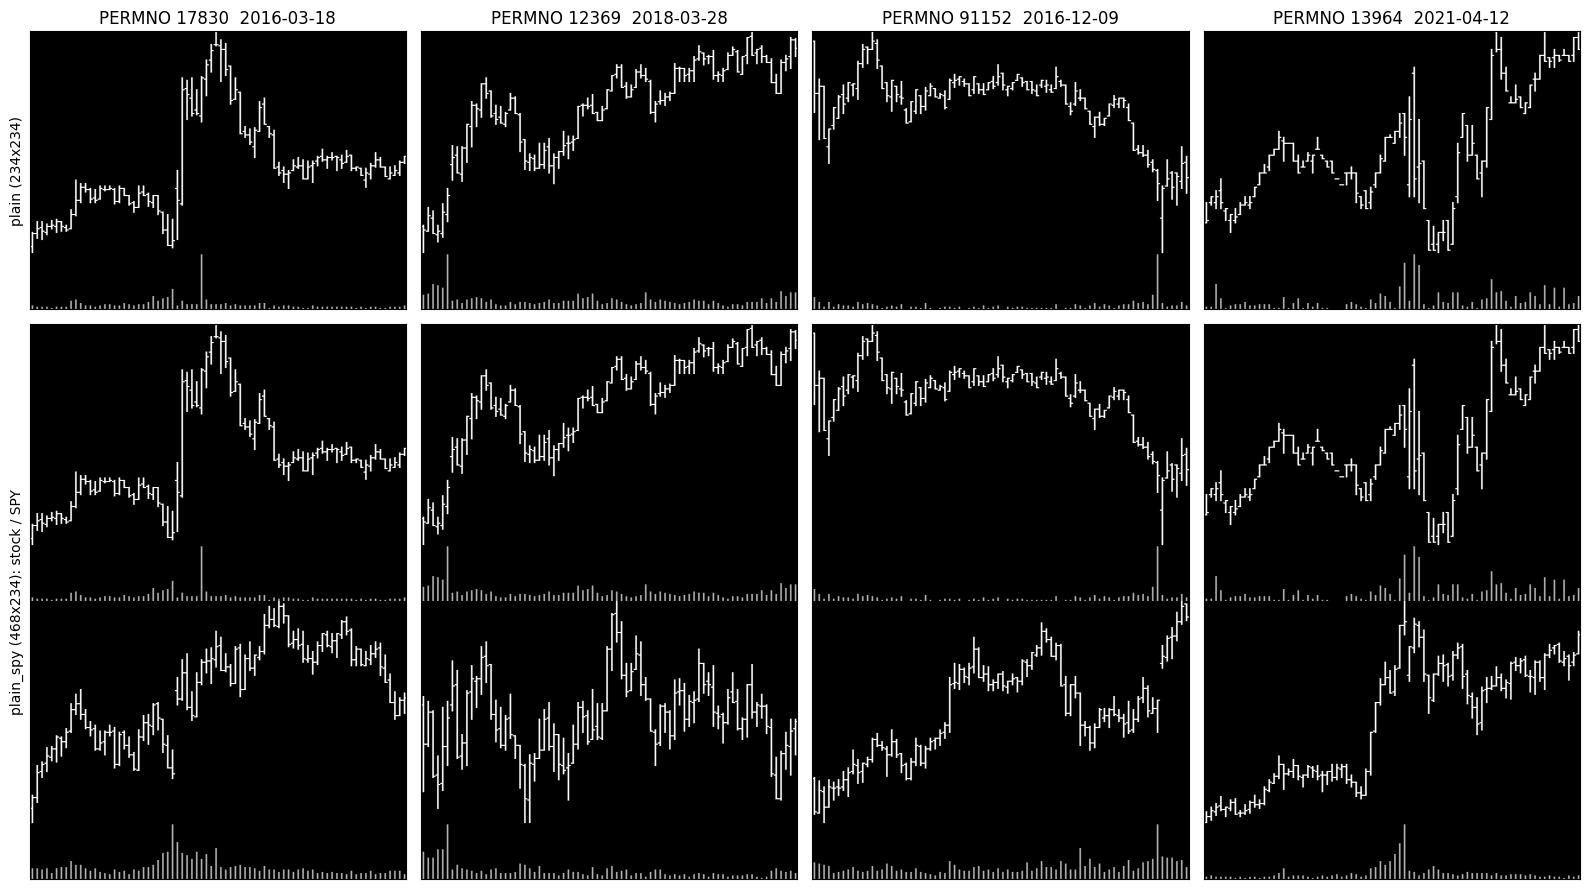

PosixPath('/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/runs/run_20261116_044159/what_models_see.png')

In [4]:
import matplotlib.pyplot as plt
sample, _ = chartcnn.build_split(store, "train", "vol", 1, STRIDE)
show = sample.sample(4, random_state=1).reset_index(drop=True)
plain, with_spy = chartcnn.make_dataset(PREPARED, show, "plain"), chartcnn.make_dataset(PREPARED, show, "plain_spy")
fig, axes = plt.subplots(2, 4, figsize=(16, 9), gridspec_kw=dict(height_ratios=[1, 2]))
for i in range(4):
    axes[0, i].imshow(plain.images(i), cmap="gray", aspect="auto")
    axes[1, i].imshow(with_spy.images(i), cmap="gray", aspect="auto")
    axes[0, i].set_title(f"PERMNO {show.permno[i]}  {store.dates[show.end_index[i]]}")
    for ax in axes[:, i]: ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("plain (234x234)"); axes[1, 0].set_ylabel("plain_spy (468x234): stock / SPY")
fig.tight_layout(); fig.savefig(RUN_LOCAL / "what_models_see.png", dpi=110); plt.show()
shutil.copy2(RUN_LOCAL / "what_models_see.png", RUN_DRIVE / "what_models_see.png")

## 5. Models
Layer-by-layer output shapes and parameter counts. Output layers start at zero, so every initial prediction is exactly 0.5.

In [5]:
for arch in ARCHS:
    data = chartcnn.make_dataset(PREPARED, show, arch)
    x = torch.stack([data[i][0] for i in range(4)])
    model = chartcnn.build_model(dict(SETTINGS, arch=arch))
    table, total, trainable = chartcnn.parameter_table(model)
    print(f"{arch} ({grid.ARCH_LABEL[arch]}): input {tuple(x.shape[1:])}, {total:,} parameters ({trainable:,} trainable)")
    display(table)
    print("initial P(y=1):", model.eval()(x).softmax(1)[:, 1].tolist(), "\n")
del model

plain (image CNN): input (1, 234, 234), 776,450 parameters (776,450 trainable)


,layer,output_shape,parameters
0,0: Conv2d,"(64, 84, 78)",1024
1,1: BatchNorm2d,"(64, 84, 78)",128
2,2: LeakyReLU,"(64, 84, 78)",0
3,3: MaxPool2d,"(64, 42, 78)",0
4,4: Conv2d,"(128, 42, 78)",123008
5,5: BatchNorm2d,"(128, 42, 78)",256
6,6: LeakyReLU,"(128, 42, 78)",0
7,7: MaxPool2d,"(128, 21, 78)",0
8,8: Conv2d,"(256, 21, 78)",491776
9,9: BatchNorm2d,"(256, 21, 78)",512


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

plain_spy (image CNN + SPY panel): input (1, 468, 234), 936,194 parameters (936,194 trainable)


,layer,output_shape,parameters
0,0: Conv2d,"(64, 162, 78)",1024
1,1: BatchNorm2d,"(64, 162, 78)",128
2,2: LeakyReLU,"(64, 162, 78)",0
3,3: MaxPool2d,"(64, 81, 78)",0
4,4: Conv2d,"(128, 81, 78)",123008
5,5: BatchNorm2d,"(128, 81, 78)",256
6,6: LeakyReLU,"(128, 81, 78)",0
7,7: MaxPool2d,"(128, 40, 78)",0
8,8: Conv2d,"(256, 40, 78)",491776
9,9: BatchNorm2d,"(256, 40, 78)",512


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

series1d (1D CNN): input (5, 78), 720,770 parameters (720,770 trainable)


,layer,output_shape,parameters
0,0: Conv1d,"(128, 78)",3328
1,1: BatchNorm1d,"(128, 78)",256
2,2: LeakyReLU,"(128, 78)",0
3,3: Conv1d,"(256, 78)",164096
4,4: BatchNorm1d,"(256, 78)",512
5,5: LeakyReLU,"(256, 78)",0
6,6: Conv1d,"(384, 78)",491904
7,7: BatchNorm1d,"(384, 78)",768
8,8: LeakyReLU,"(384, 78)",0
9,head.0: Flatten,"(29952,)",0


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

series1d_spy (1D CNN + SPY): input (10, 78), 723,970 parameters (723,970 trainable)


,layer,output_shape,parameters
0,0: Conv1d,"(128, 78)",6528
1,1: BatchNorm1d,"(128, 78)",256
2,2: LeakyReLU,"(128, 78)",0
3,3: Conv1d,"(256, 78)",164096
4,4: BatchNorm1d,"(256, 78)",512
5,5: LeakyReLU,"(256, 78)",0
6,6: Conv1d,"(384, 78)",491904
7,7: BatchNorm1d,"(384, 78)",768
8,8: LeakyReLU,"(384, 78)",0
9,head.0: Flatten,"(29952,)",0


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 



## 6. Labels
Sample counts and positive shares per cell (train 2016–2022, validation 2023). `vol` uses each stock's training-period median,
so its validation share drifts with market volatility; AUC is not affected, log loss is.

In [6]:
OVERVIEW = grid.label_overview(store, CELLS)
display(OVERVIEW.round(3)); OVERVIEW.to_csv(RUN_LOCAL / "labels.csv")

,kind,minutes,stride,train,validation,train_pos,validation_pos,validation_days
cell,,,,,,,,
vol_h12,vol,60,12,4907456,571716,0.500,0.488,247
xsdir_h12,xsdir,60,12,4899083,576346,0.500,0.500,247
dir_h12,dir,60,12,4836466,569826,0.510,0.510,247
vol_h1,vol,5,12,4957004,579533,0.500,0.477,247
xsdir_h1,xsdir,5,12,4912980,581201,0.500,0.500,247
dir_h1,dir,5,12,4715399,558713,0.505,0.503,247
vol_h6,vol,30,12,4938498,576384,0.500,0.483,247
xsdir_h6,xsdir,30,12,4926082,580755,0.500,0.500,247
dir_h6,dir,30,12,4834536,570638,0.507,0.505,247


## 7. Train the grid (validation 2023)
Per cell: labels → rules and both HGBs → the four networks → validation predictions in `runs/<RUN_ID>/<cell>/`.
Watch `val AUC`, the log-loss gain vs prior (> 0 for a useful probability) and `prob std` (≈ 0 means a collapsed CNN).

In [7]:
import time
RESULTS, t0 = {}, time.perf_counter()
for i, cell in enumerate(CELLS, 1):
    print("\n" + "=" * 20, f"[{i}/{len(CELLS)}]", cell["name"], "=" * 20)
    RESULTS[cell["name"]] = grid.run_cell(PREPARED, cell, SETTINGS, ARCHS, DEVICE, RUN_LOCAL / cell["name"],
                                          RUN_DRIVE / cell["name"], smoke=SMOKE)
    print(f"elapsed {(time.perf_counter() - t0) / 60:.1f} min")


==================== [1/12] vol_h12 ====================
vol_h12 (volatility, next 60 min, stride 12): 4,907,456 train (300,000 used by the CNNs) / 571,716 validation; positive share 0.500 / 0.488
hgb_hand_features: 16,653 tree nodes (273 trees, 20 features, 1,000,000 training rows)
hgb_hand_spy: 18,300 tree nodes (300 trees, 38 features, 1,000,000 training rows)
vol_h12 image CNN (plain): 776,450 parameters (776,450 trainable)
  batch 468/2344  loss 0.6691  acc 0.5946  1824 img/s
  batch 936/2344  loss 0.6675  acc 0.5961  1910 img/s
  batch 1404/2344  loss 0.6671  acc 0.5974  1937 img/s
  batch 1872/2344  loss 0.6656  acc 0.5989  1948 img/s
  batch 2340/2344  loss 0.6647  acc 0.5997  1953 img/s
epoch 1: train_loss 0.6647 | val AUC 0.6523 | val log loss 0.6544 (+5.59% vs prior) | prob std 0.139
  batch 468/2344  loss 0.6591  acc 0.6051  1958 img/s
  batch 936/2344  loss 0.6578  acc 0.6078  1959 img/s
  batch 1404/2344  loss 0.6582  acc 0.6072  1959 img/s
  batch 1872/2344  loss 0.6578

### Validation analysis
AUC per cell and model with 95% intervals from resampling whole validation days. The takeaways include paired
with-SPY minus without-SPY comparisons for HGB, the image CNN and the 1D CNN.

CNN (plain)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.500 [0.492, 0.507]","0.498 [0.490, 0.505]","0.499 [0.492, 0.506]","0.503 [0.498, 0.509]"
vol,"0.658 [0.650, 0.666]","0.639 [0.632, 0.647]","0.637 [0.630, 0.646]","0.649 [0.643, 0.655]"
xsdir,"0.507 [0.505, 0.509]","0.500 [0.498, 0.503]","0.501 [0.499, 0.503]","0.500 [0.498, 0.502]"


CNN (plain_spy)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.498 [0.485, 0.511]","0.496 [0.484, 0.505]","0.494 [0.484, 0.503]","0.503 [0.492, 0.514]"
vol,"0.662 [0.653, 0.670]","0.646 [0.636, 0.655]","0.634 [0.626, 0.644]","0.648 [0.641, 0.655]"
xsdir,"0.508 [0.506, 0.510]","0.500 [0.499, 0.502]","0.501 [0.500, 0.503]","0.502 [0.501, 0.504]"


CNN (series1d)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.503 [0.495, 0.511]","0.503 [0.494, 0.511]","0.495 [0.486, 0.503]","0.505 [0.498, 0.512]"
vol,"0.657 [0.649, 0.665]","0.641 [0.634, 0.649]","0.633 [0.626, 0.642]","0.650 [0.644, 0.656]"
xsdir,"0.511 [0.508, 0.513]","0.503 [0.501, 0.505]","0.504 [0.502, 0.506]","0.502 [0.499, 0.505]"


... (3 outputs left out)

,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.506 [0.498, 0.513]","0.501 [0.493, 0.507]","0.501 [0.494, 0.507]","0.506 [0.500, 0.513]"
vol,"0.684 [0.676, 0.692]","0.665 [0.658, 0.674]","0.659 [0.651, 0.668]","0.672 [0.665, 0.678]"
xsdir,"0.518 [0.515, 0.520]","0.511 [0.509, 0.513]","0.509 [0.507, 0.512]","0.506 [0.503, 0.508]"


HGB hand + SPY


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.516 [0.504, 0.526]","0.497 [0.486, 0.507]","0.498 [0.483, 0.511]","0.507 [0.494, 0.520]"
vol,"0.690 [0.682, 0.698]","0.672 [0.663, 0.680]","0.668 [0.660, 0.676]","0.680 [0.673, 0.686]"
xsdir,"0.520 [0.517, 0.523]","0.512 [0.509, 0.515]","0.510 [0.507, 0.514]","0.508 [0.504, 0.511]"


minutes  roc_auc  auc_ci_low  auc_ci_high  \
cell    model                                                                
vol_h12 rule: recent_abs_return       60   0.5775      0.5697       0.5849   
        HGB hand features             60   0.6719      0.6653       0.6776   
        HGB hand + SPY                60   0.6802      0.6728       0.6861   
        CNN (plain)                   60   0.6487      0.6428       0.6552   
        CNN (plain_spy)               60   0.6481      0.6411       0.6550   
...                                  ...      ...         ...          ...   
dir_h3  HGB hand + SPY                15   0.4968      0.4860       0.5067   
        CNN (plain)                   15   0.4983      0.4902       0.5052   
        CNN (plain_spy)               15   0.4958      0.4840       0.5050   
        CNN (series1d)                15   0.5025      0.4941       0.5113   
        CNN (series1d_spy)            15   0.5007      0.4891       0.5114   

                                 log_loss_gain_vs_prior_pct  prob_std  \
cell    model                                                           
vol_h12 rule: recent_abs_return                         NaN       NaN   
        HGB hand features                            6.9934    0.1641   
        HGB hand + SPY                               7.5783    0.1611   
        CNN (plain)                                  5.2098    0.1387   
        CNN (plain_spy)                              5.2085    0.1481   
...                                                     ...       ...   
dir_h3  HGB hand + SPY                              -0.6476    0.0411   
        CNN (plain)                                 -0.1377    0.0206   
        CNN (plain_spy)                             -1.5819    0.0662   
        CNN (series1d)                              -0.5263    0.0436   
        CNN (series1d_spy)                          -0.8034    0.0517   

                                 parameters  best_epoch  long_short_bps  \
cell    model                                                             
vol_h12 rule: recent_abs_return         NaN         NaN             NaN   
        HGB hand features           16653.0         NaN             NaN   
        HGB hand + SPY              18300.0         NaN             NaN   
        CNN (plain)                776450.0         1.0             NaN   
        CNN (plain_spy)            936194.0         3.0             NaN   
...                                     ...         ...             ...   
dir_h3  HGB hand + SPY              18300.0         NaN          1.6324   
        CNN (plain)                776450.0         1.0         -0.0614   
        CNN (plain_spy)            936194.0         2.0          0.4392   
        CNN (series1d)             720770.0         2.0          0.1860   
        CNN (series1d_spy)         723970.0         2.0          0.3586   

                                 long_short_t  validation_samples  \
cell    model                                                       
vol_h12 rule: recent_abs_return           NaN              571716   
        HGB hand features                 NaN              571716   
        HGB hand + SPY                    NaN              571716   
        CNN (plain)                       NaN              571716   
        CNN (plain_spy)                   NaN              571716   
...                                       ...                 ...   
dir_h3  HGB hand + SPY                 3.9332              568386   
        CNN (plain)                   -0.1469              568386   
        CNN (plain_spy)                1.0381              568386   
        CNN (series1d)                 0.5022              568386   
        CNN (series1d_spy)             0.8913              568386   

                                 validation_days  
cell    model                                     
vol_h12 rule: recent_abs_return              247  
        HGB hand features                

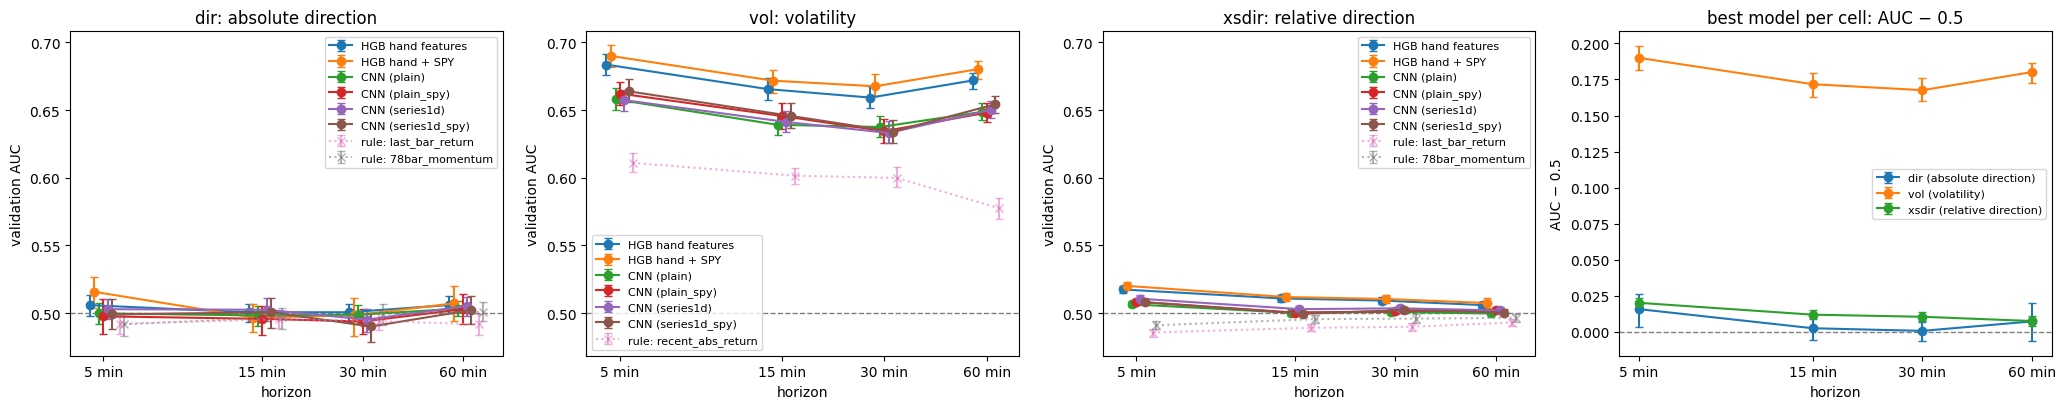

- **dir (absolute direction)**: best AUC by horizon 5 min 0.516 [0.504, 0.526] (HGB hand + SPY), 15 min 0.503 [0.494, 0.511] (CNN (series1d)), 30 min 0.501 [0.494, 0.507] (HGB hand features), 60 min 0.507 [0.494, 0.520] (HGB hand + SPY). 95% CI above 0.5 at 5 min.
- **vol (volatility)**: best AUC by horizon 5 min 0.690 [0.682, 0.698] (HGB hand + SPY), 15 min 0.672 [0.663, 0.680] (HGB hand + SPY), 30 min 0.668 [0.660, 0.676] (HGB hand + SPY), 60 min 0.680 [0.673, 0.686] (HGB hand + SPY). 95% CI above 0.5 at 5 min, 15 min, 30 min, 60 min.
- **xsdir (relative direction)**: best AUC by horizon 5 min 0.520 [0.517, 0.523] (HGB hand + SPY), 15 min 0.512 [0.509, 0.515] (HGB hand + SPY), 30 min 0.510 [0.507, 0.514] (HGB hand + SPY), 60 min 0.508 [0.504, 0.511] (HGB hand + SPY). 95% CI above 0.5 at 5 min, 15 min, 30 min, 60 min.
- dir decile long-short (top − bottom, gross, bps per horizon): dir_h1 HGB hand + SPY +1.28 bps (t = 3.11); dir_h1 CNN (plain) +0.55 bps (t = 2.32); dir_h1 CNN (series1d_spy) +0.70 bps (t = 2.35); dir_h6 HGB hand + SPY +1.38 bps (t = 2.92); dir_h3 HGB hand features +1.08 bps (t = 2.56); dir_h3 HGB hand + SPY +1.63 bps (t = 3.93)
- xsdir decile long-short (top − bottom, gross, bps per horizon): xsdir_h1 HGB hand features +1.51 bps (t = 3.00); xsdir_h1 HGB hand + SPY +1.29 bps (t = 2.27); xsdir_h1 CNN (plain_spy) +0.74 bps (t = 2.07); xsdir_h1 CNN (series1d_spy) +0.96 bps (t = 2.84); xsdir_h6 HGB hand features +1.38 bps (t = 3.11); xsdir_h3 HGB hand features +1.53 bps (t = 3.73)
- image CNN − 1D CNN AUC (paired day bootstrap) across 12 cells: better in 1, worse in 5, tied in 6.
- image CNN − HGB AUC (paired day bootstrap) across 12 cells: better in 0, worse in 8, tied in 4.
- HGB with SPY − HGB without AUC (paired day bootstrap) across 12 cells: better in 6, worse in 0, tied in 6.
- image CNN with SPY panel − without AUC (paired day bootstrap) across 12 cells: better in 3, worse in 0, tied in 9.
- 1D CNN with SPY − without AUC (paired day bootstrap) across 12 cells: better in 3, worse in 2, tied in 7.

saved to /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/runs/run_20261116_044159


In [8]:
TABLE, BOOTS = grid.grid_table(RESULTS, n_boot=50 if SMOKE else 300)
TABLE.to_csv(RUN_LOCAL / "grid_table.csv")
for model in ["CNN (plain)", "CNN (plain_spy)", "CNN (series1d)", "CNN (series1d_spy)", "HGB hand features", "HGB hand + SPY"]:
    if model in TABLE.index.get_level_values("model"):
        print(model); display(grid.auc_matrix(TABLE, model))
display(TABLE.drop(columns=["kind", "horizon"]).round(4))
grid.plot_grid(TABLE, RUN_LOCAL / "auc_by_horizon.png")
TAKEAWAYS = grid.takeaways(TABLE, BOOTS)
(RUN_LOCAL / "takeaways.md").write_text(TAKEAWAYS + "\n"); display(Markdown(TAKEAWAYS))
for name in ("labels.csv", "grid_table.csv", "auc_by_horizon.png", "takeaways.md"):
    shutil.copy2(RUN_LOCAL / name, RUN_DRIVE / name)
print("saved to", RUN_DRIVE)

## 8. Held-out test 2024–2025 (run once, at the end)
Only after every choice above is final. Each network is scored from its best validation checkpoint; HGB is refit on the
same training rows. Set `RUN_TEST = True` and run this cell. Do not change anything after looking at it.

In [9]:
RUN_TEST = SMOKE                                  # set True once, at the very end
if RUN_TEST:
    TEST = {}
    for cell in CELLS:
        folder = (RUN_LOCAL if SMOKE else RUN_DRIVE) / cell["name"]
        TEST[cell["name"]] = grid.evaluate_cell_test(PREPARED, cell, SETTINGS, ARCHS, DEVICE, folder, smoke=SMOKE)
    TEST_TABLE, TEST_BOOTS = grid.grid_table(TEST, n_boot=50 if SMOKE else 300)
    TEST_TABLE.to_csv(RUN_LOCAL / "test_grid_table.csv")
    display(TEST_TABLE.drop(columns=["kind", "horizon"]).round(4))
    display(Markdown(grid.takeaways(TEST_TABLE, TEST_BOOTS)))
    shutil.copy2(RUN_LOCAL / "test_grid_table.csv", RUN_DRIVE / "test_grid_table.csv")